
# Tutorial: Gradiente, Divergente e Rotacional no Campo de Velocidades de um Rio

Neste tutorial, vamos aprender a calcular e visualizar o gradiente, divergente e rotacional de um campo vetorial, utilizando o exemplo das velocidades de "gotas de água" em um rio de margens paralelas. Utilizaremos `sympy` para cálculos simbólicos e `matplotlib` para visualizações.

## 1. Instalando as Bibliotecas

Antes de começarmos, você precisará das bibliotecas `sympy` e `matplotlib`. Se ainda não tiver, pode instalá-las com:

```bash
pip install sympy matplotlib
```

## 2. Importando as Bibliotecas

Vamos importar as bibliotecas necessárias para cálculos simbólicos e visualização.


In [13]:

import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from sympy.vector import CoordSys3D, gradient, divergence, curl



## 3. Campo Vetorial de Velocidades no Rio

Imagine um rio de margens paralelas, onde a água flui mais rápido no centro e mais devagar nas margens devido ao atrito. Podemos modelar o campo vetorial das velocidades ${V}(x, y)$ da água como:

$$
\vec{V}(x, y) = V_0 \cdot \left(1 - \frac{y^2}{a^2} \right) \bf{\hat{i}}
$$

Aqui:
- $ V_0 $ é a velocidade máxima no centro do rio.
- $ a $ é a distância do centro até as margens.
- $ y $ é a posição transversal à direção do fluxo (ao longo de \( x \)).

Vamos definir o sistema de coordenadas e o campo vetorial.
    

In [17]:

# Definir o sistema de coordenadas
N = CoordSys3D('N')

# Definir o campo escalar e vetorial
V0, a = sp.symbols('V0 a')
V = V0 * (1 - (N.y ** 2) / a**2) * N.i
V

(V0*(-N.y**2/a**2 + 1))*N.i

In [18]:

# Campo escalar (velocidade escalar no rio)
phi = V0 * (1 - (N.y ** 2) / a**2)  # Campo escalar
phi

V0*(-N.y**2/a**2 + 1)


## 4. Gradiente no Campo de Velocidades

O gradiente de um campo escalar nos diz a direção da maior variação. No contexto do rio, podemos calcular como a velocidade varia transversalmente ao fluxo. Aqui calcularemos o gradiente da componente da velocidade no eixo $ x $.

$$
\vec {\nabla} \cdot \vec{V}(x, y) = \frac{d}{dy} \left( V_0 \cdot \left( 1 - \frac{y^2}{a^2} \right)  \right)
$$
    

In [19]:
# Calcular o gradiente do campo escalar
gradiente_phi = gradient(phi)
gradiente_phi

(-2*N.y*V0/a**2)*N.j


## 5. Divergente no Campo de Velocidades

O divergente nos diz se o fluido está sendo "criado" ou "destruído". Para um rio com fluxo constante, esperamos que o divergente seja zero, indicando que não há fontes ou sumidouros.

Vamos calcular o divergente de \(
ec{V}(x, y) \).

\[

ec{
\nabla} \cdot
ec{V}(x, y) = 0
\]
    

In [21]:

# Calcular o divergente
divergente_V = divergence(V)
divergente_V


0


## 6. Rotacional no Campo de Velocidades

O rotacional nos diz se o fluido tem tendência a "girar" ao redor de um ponto. Um campo sem vorticidade tem rotacional zero.

Vamos calcular o rotacional de \(
ec{V}(x, y) \).

\[

ec{
abla} 	imes
ec{V}(x, y) = 0
\]
    

In [22]:

# Calcular o rotacional
rotacional_V = curl(V)
rotacional_V


2*N.y*V0/a**2*N.k


## 7. Visualizando o Campo Vetorial

Agora, vamos visualizar o campo de velocidades \(
ec{V}(x, y) \) ao longo do rio, mostrando que a velocidade é maior no centro e menor nas margens.

    

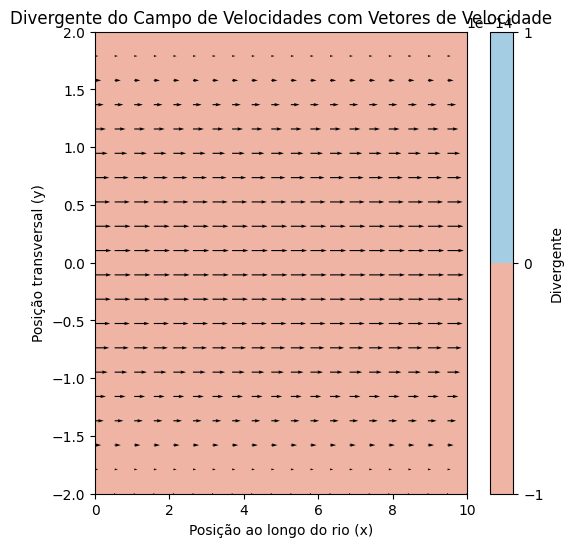

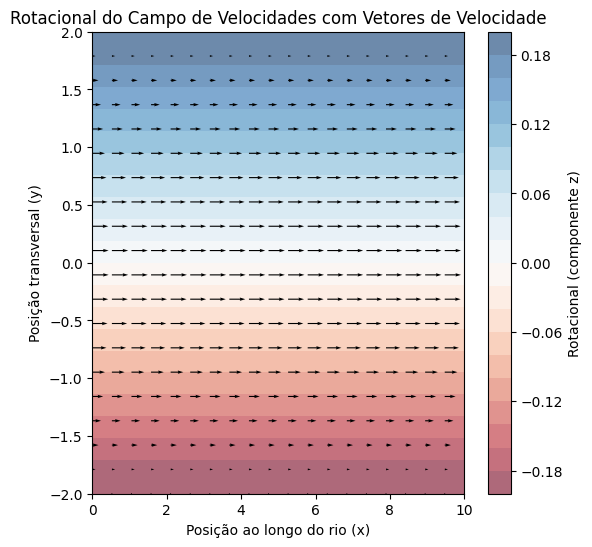

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Definir a malha
x = np.linspace(0, 10, 20)
y = np.linspace(-2, 2, 20)
X, Y = np.meshgrid(x, y)

# Campo de velocidades no eixo x (máximo no centro)
V0 = 1
a = 2
Vx = V0 * (1 - (Y**2 / a**2))
Vy = np.zeros_like(Vx)

# Calcular o divergente numericamente (aproximação de derivadas parciais)
dVx_dx = np.gradient(Vx, axis=1)
dVy_dy = np.gradient(Vy, axis=0)
divergente = dVx_dx + dVy_dy

# Calcular o rotacional (somente a componente z)
dVy_dx = np.gradient(Vy, axis=1)
dVx_dy = np.gradient(Vx, axis=0)
rotacional_z = dVy_dx - dVx_dy

# Visualizando o divergente com campo de velocidades sobreposto
plt.figure(figsize=(6, 6))
plt.contourf(X, Y, divergente, cmap='RdBu', levels=20, alpha=0.6)  # Heatmap do divergente
plt.colorbar(label='Divergente')
plt.quiver(X, Y, Vx, Vy, color='black')  # Campo de velocidades sobreposto
plt.title('Divergente do Campo de Velocidades com Vetores de Velocidade')
plt.xlabel('Posição ao longo do rio (x)')
plt.ylabel('Posição transversal (y)')
plt.show()

# Visualizando o rotacional com campo de velocidades sobreposto
plt.figure(figsize=(6, 6))
plt.contourf(X, Y, rotacional_z, cmap='RdBu', levels=20, alpha=0.6)  # Heatmap do rotacional
plt.colorbar(label='Rotacional (componente z)')
plt.quiver(X, Y, Vx, Vy, color='black')  # Campo de velocidades sobreposto
plt.title('Rotacional do Campo de Velocidades com Vetores de Velocidade')
plt.xlabel('Posição ao longo do rio (x)')
plt.ylabel('Posição transversal (y)')
plt.show()
